In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import os

In [2]:
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/ETL/data_processed/dados_convertidos_mat_para_csv.csv"
output_path = os.path.join(output_dir, "dados_corregidos_msc.csv")


In [3]:
df = pd.read_csv(output_dir)
data = df.values

In [4]:
espectro_referencia = np.mean(data, axis=0).reshape(-1, 1)
bandas_corrigidas = np.zeros_like(data)

for i in range(data.shape[0]):
    amostra = data[i, :].reshape(-1, 1)
    modelo = LinearRegression().fit(espectro_referencia, amostra)
    inclinacao = modelo.coef_[0][0]
    intercepto = modelo.intercept_[0]
    bandas_corrigidas[i, :] = (data[i, :] - intercepto) / inclinacao

df_corrigido = pd.DataFrame(bandas_corrigidas, columns=df.columns)

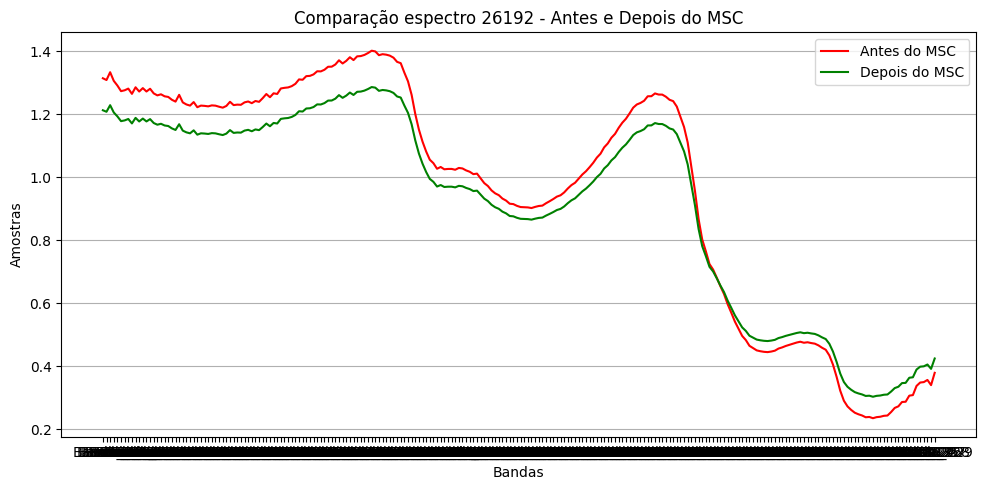

In [5]:
idx = np.random.randint(0, data.shape[0])
plt.figure(figsize=(10, 5))

plt.plot(data[idx], label="Antes do MSC", color="red")
plt.plot(df_corrigido.iloc[idx], label="Depois do MSC", color="green")

plt.title(f"Comparação espectro {idx} - Antes e Depois do MSC")
plt.xlabel("Bandas")
plt.ylabel("Amostras")
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [ ]:
df_corrigido = pd.DataFrame(bandas_corrigidas, columns=df.columns)
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_corrigido.to_csv(output_path, index=False)